# Context-reviewed vernacular analysis: 218 entries
Extract the ZIP first. Keep this notebook and dialect_review_218_CONTEXT_REVIEWED.csv in the same folder. Run all cells from top to bottom. The original 218-entry master is included.
The CSV preserves 7,721 earlier annotations and adds an AI-assisted KWIC review of 1,495 candidates. There is no independent human adjudication. Uncertain cases are retained in the CSV but omitted from main totals. No claim is made that all 39 books were reread. Historical/register exclusions are analytical choices; source definitions and reasons appear in the review.
This reproduces reviewed corpus, G² and Twain quotation results. It does not update character-level rates or the child-corpus quotation comparison.


## 1. Load the 39 texts

In [4]:
from pathlib import Path
from collections import Counter
import re
import pandas as pd

BASE_PATH = Path("/Users/manalaltammami/Desktop/twain_child_corpus")
TOKEN_PATTERN = re.compile(r"[a-z]+(?:['-][a-z]+)*")

def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower().replace("’", "'"))

twain_files = ['Tom_Sawyer_narrative.txt', 'Huckleberry_Finn_narrative.txt', 'Prince_and_the_Pauper_narrative.txt']

child_files = ['Ragged_Dick_narrative.txt', 'Little_Women_narrative.txt', 'An_Old_Fashioned_Girl_narrative.txt', 'Toby_Tyler_narrative.txt', 'Five_Little_Peppers_narrative.txt', 'Hoosier_Schoolboy_narrative.txt', 'Little_Lord_Fauntleroy_narrative.txt', 'The_Story_of_Patsy_narrative.txt']

adult_files = ['Silas_Lapham_narrative.txt', 'Ministers_Charge_narrative.txt', 'Hazard_New_Fortunes_narrative.txt', 'Portrait_of_a_Lady_narrative.txt', 'Bostonians_narrative.txt', 'Washington_Square_narrative.txt', 'Pointed_Firs_narrative.txt', 'Deephaven_narrative.txt', 'Country_Doctor_narrative.txt', 'Awakening_narrative.txt', 'Graysons_narrative.txt', 'McTeague_narrative.txt', 'Octopus_narrative.txt', 'Red_Badge_of_Courage_narrative.txt', 'Maggie_narrative.txt', 'Main_Travelled_Roads_narrative.txt', 'Old_Creole_Days_narrative.txt', 'Conjure_Woman_narrative.txt', 'Looking_Backward_narrative.txt', 'Theron_Ware_narrative.txt', 'Sister_Carrie_narrative.txt', 'Summer_narrative.txt', 'Scarlet_Letter_narrative.txt', 'Seven_Gables_narrative.txt', 'Moby_Dick_narrative.txt', 'Aspern_Papers_narrative.txt', 'Bartleby_narrative.txt', 'Benito_Cereno_narrative.txt']

EXPECTED_BOOK_TOKENS = {'Tom_Sawyer_narrative.txt': 70518, 'Huckleberry_Finn_narrative.txt': 110729, 'Prince_and_the_Pauper_narrative.txt': 67007, 'Ragged_Dick_narrative.txt': 47722, 'Little_Women_narrative.txt': 185825, 'An_Old_Fashioned_Girl_narrative.txt': 101818, 'Toby_Tyler_narrative.txt': 50233, 'Five_Little_Peppers_narrative.txt': 69400, 'Hoosier_Schoolboy_narrative.txt': 36080, 'Little_Lord_Fauntleroy_narrative.txt': 58627, 'The_Story_of_Patsy_narrative.txt': 11359, 'Silas_Lapham_narrative.txt': 129245, 'Ministers_Charge_narrative.txt': 115995, 'Hazard_New_Fortunes_narrative.txt': 163596, 'Portrait_of_a_Lady_narrative.txt': 225399, 'Bostonians_narrative.txt': 162770, 'Washington_Square_narrative.txt': 64180, 'Pointed_Firs_narrative.txt': 41980, 'Deephaven_narrative.txt': 54924, 'Country_Doctor_narrative.txt': 89552, 'Awakening_narrative.txt': 49937, 'Graysons_narrative.txt': 91482, 'McTeague_narrative.txt': 113374, 'Octopus_narrative.txt': 196738, 'Red_Badge_of_Courage_narrative.txt': 46161, 'Maggie_narrative.txt': 22703, 'Main_Travelled_Roads_narrative.txt': 85788, 'Old_Creole_Days_narrative.txt': 68616, 'Conjure_Woman_narrative.txt': 37553, 'Looking_Backward_narrative.txt': 77303, 'Theron_Ware_narrative.txt': 119128, 'Sister_Carrie_narrative.txt': 156121, 'Summer_narrative.txt': 57454, 'Scarlet_Letter_narrative.txt': 68587, 'Seven_Gables_narrative.txt': 103524, 'Moby_Dick_narrative.txt': 209312, 'Aspern_Papers_narrative.txt': 39083, 'Bartleby_narrative.txt': 14456, 'Benito_Cereno_narrative.txt': 31472}

corpora = {"Twain": twain_files, "Child": child_files, "Adult": adult_files}
expected_totals = {"Twain": 248254, "Child": 561064, "Adult": 2636433}
all_files = [name for files in corpora.values() for name in files]
if len(all_files) != 39 or len(set(all_files)) != 39:
    raise ValueError("Expected 39 unique narrative files.")
missing = [name for name in all_files if not (BASE_PATH / name).is_file()]
if missing:
    raise FileNotFoundError("Missing narrative files:\n" + "\n".join(missing))

source_texts = {}
for corpus, files in corpora.items():
    for filename in files:
        text = (BASE_PATH / filename).read_text(encoding="utf-8")
        if len(tokenize(text)) != EXPECTED_BOOK_TOKENS[filename]:
            raise ValueError(f"Token total changed: {filename}")
        source_texts[filename] = text
    print(corpus, f"{sum(len(tokenize(source_texts[f])) for f in files):,}", "tokens")
print("All 39 texts loaded. Source files are unchanged.")


Twain 248,254 tokens
Child 561,064 tokens
Adult 2,636,433 tokens
All 39 texts loaded. Source files are unchanged.


## 2. Master lexicon (included in this notebook)

In [7]:
# MASTER VERNACULAR LEXICON — consolidated 2 November 2026
# Preserves all 208 entries from the latest uploaded master and adds 10.
# 218 distinct entries: 114 dialectal and 104 colloquial; no overlap.
# Source attributions inherited from the original inventory unless noted.
# The ten added entries have Rasmussen 2007 page references and senses.
# Category labels are analytical classifications, not uniform labels in the sources.
# pickins is colloquial only; Carkeet 1979 p.320 places it among lexical features.
# Lexicon membership is separate from whether an occurrence has the intended sense.
# Expanded-corpus results must be recalculated before updating the paper.
# The matcher must explicitly support variants metadata (gospel sharp/gospel-sharp).

MASTER_VERNACULAR = {'fantods': {'type': 'colloquial', 'source': ['Buxbaum']},
 'right smart': {'type': 'colloquial', 'source': ['Buxbaum']},
 'right smart chance': {'type': 'colloquial', 'source': ['Buxbaum']},
 'used to was': {'type': 'colloquial', 'source': ['Buxbaum']},
 'take soundings': {'type': 'colloquial', 'source': ['Buxbaum']},
 'give down the banks': {'type': 'colloquial', 'source': ['Buxbaum']},
 'washed back': {'type': 'colloquial', 'source': ['Buxbaum']},
 'breakers ahead': {'type': 'colloquial', 'source': ['Buxbaum']},
 'mooning': {'type': 'colloquial', 'source': ['Buxbaum']},
 'googooing': {'type': 'colloquial', 'source': ['Buxbaum']},
 'blethers': {'type': 'colloquial', 'source': ['Buxbaum']},
 'blatters': {'type': 'colloquial', 'source': ['Buxbaum']},
 'skaddled': {'type': 'colloquial', 'source': ['Buxbaum']},
 'haggles': {'type': 'colloquial', 'source': ['Buxbaum']},
 'flapdoodle': {'type': 'colloquial', 'source': ['Buxbaum']},
 'swabbing': {'type': 'colloquial', 'source': ['Buxbaum']},
 'gaudy': {'type': 'colloquial', 'source': ['Buxbaum']},
 'gumption': {'type': 'colloquial', 'source': ['MTPO']},
 'pow-wow': {'type': 'colloquial', 'source': ['MTPO']},
 'whollop': {'type': 'colloquial', 'source': ['MTPO']},
 'scoop': {'type': 'colloquial', 'source': ['MTPO']},
 'show up': {'type': 'colloquial', 'source': ['MTPO']},
 'swap around': {'type': 'colloquial', 'source': ['MTPO']},
 'spread around': {'type': 'colloquial', 'source': ['MTPO']},
 'stand from under': {'type': 'colloquial', 'source': ['MTPO']},
 'dog my cats': {'type': 'colloquial', 'source': ['MTPO']},
 'gone to grass': {'type': 'colloquial', 'source': ['MTPO']},
 'freeze': {'type': 'colloquial', 'source': ['MTPO']},
 'gabble': {'type': 'colloquial', 'source': ['MTPO']},
 'hunch': {'type': 'colloquial', 'source': ['MTPO']},
 'holt': {'type': 'colloquial', 'source': ['MTPO', 'Carkeet']},
 'size their style': {'type': 'colloquial', 'source': ['MTPO']},
 'close place': {'type': 'colloquial', 'source': ['MTPO']},
 'cross off': {'type': 'colloquial', 'source': ['MTPO']},
 'spread-eagle': {'type': 'colloquial', 'source': ['MTPO']},
 'slop': {'type': 'colloquial', 'source': ['MTPO']},
 'boss': {'type': 'colloquial', 'source': ['MTPO']},
 'boom': {'type': 'colloquial', 'source': ['MTPO']},
 'booming': {'type': 'colloquial', 'source': ['MTPO']},
 'blatherskite': {'type': 'colloquial', 'source': ['Rasmussen']},
 'blister': {'type': 'colloquial', 'source': ['Rasmussen']},
 'brickbat': {'type': 'colloquial', 'source': ['Rasmussen']},
 'bulge': {'type': 'colloquial', 'source': ['Rasmussen']},
 'bullyrag': {'type': 'colloquial', 'source': ['Rasmussen']},
 'buncombe': {'type': 'colloquial', 'source': ['Rasmussen']},
 'chin music': {'type': 'colloquial', 'source': ['Rasmussen']},
 'cornpone': {'type': 'colloquial', 'source': ['Rasmussen']},
 'crawfish': {'type': 'colloquial', 'source': ['Rasmussen']},
 'dead-head': {'type': 'colloquial', 'source': ['Rasmussen']},
 'disremember': {'type': 'colloquial', 'source': ['Rasmussen']},
 'doggery': {'type': 'colloquial', 'source': ['Rasmussen']},
 'doodle-bug': {'type': 'colloquial', 'source': ['Rasmussen']},
 'galoot': {'type': 'colloquial', 'source': ['Rasmussen']},
 'galluses': {'type': 'colloquial', 'source': ['Rasmussen']},
 'gin-mill': {'type': 'colloquial', 'source': ['Rasmussen']},
 'hive': {'type': 'colloquial', 'source': ['Rasmussen']},
 'honor bright': {'type': 'colloquial', 'source': ['Rasmussen']},
 'hump oneself': {'type': 'colloquial', 'source': ['Rasmussen']},
 'jim-jams': {'type': 'colloquial', 'source': ['Rasmussen']},
 'lagniappe': {'type': 'colloquial', 'source': ['Rasmussen']},
 'lam': {'type': 'colloquial', 'source': ['Rasmussen']},
 'muggins': {'type': 'colloquial', 'source': ['Rasmussen']},
 'mullet-headed': {'type': 'colloquial', 'source': ['Rasmussen']},
 'ornery': {'type': 'colloquial', 'source': ['Rasmussen']},
 'pard': {'type': 'colloquial', 'source': ['Rasmussen']},
 'peach': {'type': 'colloquial', 'source': ['Rasmussen']},
 "pudd'nhead": {'type': 'colloquial', 'source': ['Rasmussen']},
 'reckon': {'type': 'colloquial', 'source': ['Rasmussen']},
 'roustabout': {'type': 'colloquial', 'source': ['Rasmussen']},
 'rubbage': {'type': 'colloquial', 'source': ['Rasmussen']},
 'sand': {'type': 'colloquial', 'source': ['Rasmussen']},
 'sawbones': {'type': 'colloquial', 'source': ['Rasmussen']},
 'scrouge': {'type': 'colloquial', 'source': ['Rasmussen']},
 'shucks': {'type': 'colloquial', 'source': ['Rasmussen']},
 'slouch': {'type': 'colloquial', 'source': ['Rasmussen']},
 'slumgullion': {'type': 'colloquial', 'source': ['Rasmussen']},
 'sockdolager': {'type': 'colloquial', 'source': ['Rasmussen']},
 'spondulicks': {'type': 'colloquial', 'source': ['Rasmussen']},
 'spunk-water': {'type': 'colloquial', 'source': ['Rasmussen']},
 'such another': {'type': 'colloquial', 'source': ['Rasmussen']},
 'summerset': {'type': 'colloquial', 'source': ['Rasmussen']},
 'tumble-bug': {'type': 'colloquial', 'source': ['Rasmussen']},
 'wildcat': {'type': 'colloquial', 'source': ['Rasmussen']},
 'palaver': {'type': 'colloquial', 'source': ['Carkeet']},
 "hifalutin'": {'type': 'colloquial', 'source': ['Carkeet']},
 'sasser': {'type': 'colloquial', 'source': ['Carkeet']},
 'pickins': {'type': 'colloquial', 'source': ['Carkeet']},
 'jigger': {'type': 'colloquial', 'source': ['Carkeet']},
 'big-bug': {'type': 'colloquial', 'source': ['Carkeet']},
 'pungle': {'type': 'colloquial', 'source': ['Carkeet']},
 'Old Harry': {'type': 'colloquial', 'source': ['Carkeet']},
 'pass': {'type': 'colloquial', 'source': ['Carkeet']},
 'hook': {'type': 'colloquial', 'source': ['Carkeet']},
 'whoo-oop': {'type': 'colloquial', 'source': ['Carkeet']},
 'unfavorable to': {'type': 'colloquial', 'source': ['Carkeet']},
 'jist': {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 'chaw': {'type': 'dialect', 'source': ['Buxbaum']},
 'tobacker': {'type': 'dialect', 'source': ['Buxbaum']},
 "borry'd": {'type': 'dialect', 'source': ['Buxbaum']},
 "off'n": {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 'intrust': {'type': 'dialect', 'source': ['Buxbaum']},
 'nuther': {'type': 'dialect', 'source': ['Buxbaum']},
 'snew': {'type': 'dialect', 'source': ['Buxbaum']},
 'ketch': {'type': 'dialect', 'source': ['Buxbaum']},
 "'low": {'type': 'dialect', 'source': ['Buxbaum']},
 'haint': {'type': 'dialect', 'source': ['Buxbaum']},
 "warn't": {'type': 'dialect', 'source': ['Buxbaum']},
 'crick': {'type': 'dialect', 'source': ['Buxbaum']},
 'gethered': {'type': 'dialect', 'source': ['Buxbaum']},
 'yallar': {'type': 'dialect', 'source': ['Buxbaum']},
 'ben': {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 'cheer': {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 'sence': {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 'pore': {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 'whar': {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 "h'yer": {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 'kin': {'type': 'dialect', 'source': ['Buxbaum']},
 'sorrer': {'type': 'dialect', 'source': ['Buxbaum']},
 'alluz': {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 'clost': {'type': 'dialect', 'source': ['Buxbaum']},
 'deffersit': {'type': 'dialect', 'source': ['Buxbaum']},
 "g'yrls": {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 'sh-she': {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 "s'i": {'type': 'dialect', 'source': ['Buxbaum', 'Carkeet']},
 'chile': {'type': 'dialect', 'source': ['MTPO']},
 'chimbly': {'type': 'dialect', 'source': ['MTPO']},
 'clumb': {'type': 'dialect', 'source': ['MTPO']},
 'injin': {'type': 'dialect', 'source': ['MTPO']},
 'mars': {'type': 'dialect', 'source': ['MTPO']},
 'widder': {'type': 'dialect', 'source': ['MTPO']},
 "hain't": {'type': 'dialect', 'source': ['MTPO']},
 'wuz': {'type': 'dialect', 'source': ['MTPO']},
 'knowed': {'type': 'dialect', 'source': ['MTPO']},
 "reck'n": {'type': 'dialect', 'source': ['MTPO']},
 'anywheres': {'type': 'dialect', 'source': ['MTPO']},
 "more'n": {'type': 'dialect', 'source': ['MTPO']},
 'ef': {'type': 'dialect', 'source': ['MTPO']},
 'en': {'type': 'dialect', 'source': ['MTPO']},
 'uv': {'type': 'dialect', 'source': ['MTPO']},
 "you's": {'type': 'dialect', 'source': ['MTPO']},
 'agin': {'type': 'dialect', 'source': ['MTPO']},
 'ole': {'type': 'dialect', 'source': ['MTPO']},
 "jis'": {'type': 'dialect', 'source': ['MTPO']},
 'riber': {'type': 'dialect', 'source': ['MTPO']},
 "po'": {'type': 'dialect', 'source': ['MTPO']},
 "fo'": {'type': 'dialect', 'source': ['MTPO']},
 'sich': {'type': 'dialect', 'source': ['MTPO', 'Carkeet']},
 'dat': {'type': 'dialect', 'source': ['Rasmussen']},
 'deef': {'type': 'dialect', 'source': ['Rasmussen']},
 "'deed": {'type': 'dialect', 'source': ['Rasmussen']},
 'gwine': {'type': 'dialect', 'source': ['Rasmussen']},
 'et': {'type': 'dialect', 'source': ['Rasmussen']},
 'marse': {'type': 'dialect', 'source': ['Rasmussen']},
 'yaller': {'type': 'dialect', 'source': ['Rasmussen']},
 "p'fessor": {'type': 'dialect', 'source': ['Carkeet']},
 "suthin'": {'type': 'dialect', 'source': ['Carkeet']},
 'fitten': {'type': 'dialect', 'source': ['Carkeet']},
 'wust': {'type': 'dialect', 'source': ['Carkeet']},
 'orter': {'type': 'dialect', 'source': ['Carkeet']},
 "out'n": {'type': 'dialect', 'source': ['Carkeet']},
 'yander': {'type': 'dialect', 'source': ['Carkeet']},
 'thar': {'type': 'dialect', 'source': ['Carkeet']},
 'awready': {'type': 'dialect', 'source': ['Carkeet']},
 "cain't": {'type': 'dialect', 'source': ['Carkeet']},
 'wunst': {'type': 'dialect', 'source': ['Carkeet']},
 'tech': {'type': 'dialect', 'source': ['Carkeet']},
 'jedge': {'type': 'dialect', 'source': ['Carkeet']},
 'yit': {'type': 'dialect', 'source': ['Carkeet']},
 'sech': {'type': 'dialect', 'source': ['Carkeet']},
 'childern': {'type': 'dialect', 'source': ['Carkeet']},
 'shet': {'type': 'dialect', 'source': ['Carkeet']},
 'forgit': {'type': 'dialect', 'source': ['Carkeet']},
 'hearn': {'type': 'dialect', 'source': ['Carkeet']},
 'amost': {'type': 'dialect', 'source': ['Carkeet']},
 'kiver': {'type': 'dialect', 'source': ['Carkeet']},
 'natcherl': {'type': 'dialect', 'source': ['Carkeet']},
 'vrack': {'type': 'dialect', 'source': ['Carkeet']},
 'furder': {'type': 'dialect', 'source': ['Carkeet']},
 'Sent Louis': {'type': 'dialect', 'source': ['Carkeet']},
 'squench': {'type': 'dialect', 'source': ['Carkeet']},
 'considable': {'type': 'dialect', 'source': ['Carkeet']},
 'drot': {'type': 'dialect', 'source': ['Carkeet']},
 'partickler': {'type': 'dialect', 'source': ['Carkeet']},
 'owdacious': {'type': 'dialect', 'source': ['Carkeet']},
 "clo'es": {'type': 'dialect', 'source': ['Carkeet']},
 'Newrleans': {'type': 'dialect', 'source': ['Carkeet']},
 'reely': {'type': 'dialect', 'source': ['Carkeet']},
 'that-air': {'type': 'dialect', 'source': ['Carkeet']},
 'Brer': {'type': 'dialect', 'source': ['Carkeet']},
 'borry': {'type': 'dialect', 'source': ['Carkeet']},
 "befo'": {'type': 'dialect', 'source': ['Carkeet']},
 "yo'": {'type': 'dialect', 'source': ['Carkeet']},
 "he'p": {'type': 'dialect', 'source': ['Carkeet']},
 'misable': {'type': 'dialect', 'source': ['Carkeet']},
 "k'yer": {'type': 'dialect', 'source': ['Carkeet']},
 "these-'yer": {'type': 'dialect', 'source': ['Carkeet']},
 'thish-yer': {'type': 'dialect', 'source': ['Carkeet']},
 'wisht': {'type': 'dialect', 'source': ['Carkeet']},
 'hunderd': {'type': 'dialect', 'source': ['Carkeet']},
 'ye': {'type': 'dialect', 'source': ['Carkeet']},
 'fust': {'type': 'dialect', 'source': ['Carkeet']},
 'shore': {'type': 'dialect', 'source': ['Carkeet']},
 'Babtist': {'type': 'dialect', 'source': ['Carkeet']},
 "bar'l": {'type': 'dialect', 'source': ['Carkeet']},
 "f'm": {'type': 'dialect', 'source': ['Carkeet']},
 'waw-path': {'type': 'dialect', 'source': ['Carkeet']},
 "'t": {'type': 'dialect', 'source': ['Carkeet']},
 "'at": {'type': 'dialect', 'source': ['Carkeet']},
 'blame my cats': {'type': 'colloquial',
                   'source': ['Rasmussen'],
                   'source_year': 2007,
                   'page': 1057,
                   'sense': 'Expression of surprise',
                   'classification_note': 'Category assigned for this inventory; glossary '
                                          'inclusion alone is not an explicit category label '
                                          'from Rasmussen.'},
 'bile': {'type': 'dialect',
          'source': ['Rasmussen'],
          'source_year': 2007,
          'page': 1057,
          'sense': 'Nonstandard form of boil',
          'classification_note': 'Category assigned for this inventory; glossary inclusion '
                                 'alone is not an explicit category label from Rasmussen.'},
 'doxology-works': {'type': 'colloquial',
                    'source': ['Rasmussen'],
                    'source_year': 2007,
                    'page': 1060,
                    'sense': 'Western slang for a church',
                    'classification_note': 'Category assigned for this inventory; glossary '
                                           'inclusion alone is not an explicit category label '
                                           'from Rasmussen.'},
 'flathead': {'type': 'colloquial',
              'source': ['Rasmussen'],
              'source_year': 2007,
              'page': 1060,
              'sense': 'Inexperienced or foolish person',
              'classification_note': 'Category assigned for this inventory; glossary '
                                     'inclusion alone is not an explicit category label from '
                                     'Rasmussen.'},
 'forty-rod': {'type': 'colloquial',
               'source': ['Rasmussen'],
               'source_year': 2007,
               'page': 1061,
               'sense': 'Cheap whiskey',
               'classification_note': 'Category assigned for this inventory; glossary '
                                      'inclusion alone is not an explicit category label from '
                                      'Rasmussen.'},
 'gospel sharp': {'type': 'colloquial',
                  'source': ['Rasmussen'],
                  'source_year': 2007,
                  'page': 1061,
                  'sense': 'Christian minister',
                  'classification_note': 'Category assigned for this inventory; glossary '
                                         'inclusion alone is not an explicit category label '
                                         'from Rasmussen.',
                  'variants': ['gospel sharp', 'gospel-sharp']},
 'gospel-mill': {'type': 'colloquial',
                 'source': ['Rasmussen'],
                 'source_year': 2007,
                 'page': 1061,
                 'sense': 'Church',
                 'classification_note': 'Category assigned for this inventory; glossary '
                                        'inclusion alone is not an explicit category label '
                                        'from Rasmussen.'},
 'jack-leg': {'type': 'colloquial',
              'source': ['Rasmussen'],
              'source_year': 2007,
              'page': 1062,
              'sense': 'Improvised or makeshift in Twain usage',
              'classification_note': 'Category assigned for this inventory; glossary '
                                     'inclusion alone is not an explicit category label from '
                                     'Rasmussen.'},
 'leather-face': {'type': 'colloquial',
                  'source': ['Rasmussen'],
                  'source_year': 2007,
                  'page': 1063,
                  'sense': 'Someone whose face conceals emotion',
                  'classification_note': 'Category assigned for this inventory; glossary '
                                         'inclusion alone is not an explicit category label '
                                         'from Rasmussen.'},
 'leather-head': {'type': 'colloquial',
                  'source': ['Rasmussen'],
                  'source_year': 2007,
                  'page': 1063,
                  'sense': 'Foolish or unintelligent person',
                  'classification_note': 'Category assigned for this inventory; glossary '
                                         'inclusion alone is not an explicit category label '
                                         'from Rasmussen.'}}

# Check totals.
from collections import Counter

category_counts = Counter()
for entry in MASTER_VERNACULAR.values():
    categories = entry["type"]
    if isinstance(categories, str):
        categories = [categories]
    category_counts.update(set(categories))

print("Distinct entries:", len(MASTER_VERNACULAR))
print("Dialectal entries:", category_counts["dialect"])
print("Colloquial entries:", category_counts["colloquial"])

assert len(MASTER_VERNACULAR) == 218
assert category_counts["dialect"] == 114
assert category_counts["colloquial"] == 104


Distinct entries: 218
Dialectal entries: 114
Colloquial entries: 104


## 3. Load the contextual decisions and calculate counts
No new automatic counting is substituted for the reviewed decisions.


In [14]:
from pathlib import Path
from collections import Counter
import pandas as pd

review_path = (
    Path.home()
    / "Downloads"
    / "Vernacular_218_Context_Review"
    / "dialect_review_218_CONTEXT_REVIEWED.csv"
)

if not review_path.is_file():
    raise FileNotFoundError(f"Review CSV not found: {review_path}")

review = pd.read_csv(review_path, keep_default_na=False)
review["Decision"] = review["Decision"].str.strip()

print("Loading:", review_path)
print(review["Decision"].value_counts().to_string())

if (
    len(review) != 9216
    or review["Decision"].str.contains(
        "Pending", case=False
    ).any()
    or review["Decision"].eq("").any()
):
    raise ValueError("The review file is incomplete or unexpected.")

included = review.loc[
    review["Decision"].eq("Include")
].copy()

# Confirm that the review matches the loaded source texts.
for row in review.to_dict("records"):
    start = int(row["Start"])
    end = int(row["End"])
    text = source_texts[row["File"]]

    if (
        not 0 <= start < end <= len(text)
        or text[start:end] != row["Matched wording"]
    ):
        raise ValueError(
            f"Source text differs: {row['File']}, "
            f"candidate {row['Candidate ID']}"
        )

matches_by_file = {}
rows = []

for corpus, files in corpora.items():
    for filename in files:
        book_matches = included.loc[
            included["File"].eq(filename)
        ]

        found = [
            (int(row["Start"]), int(row["End"]), row["Term"])
            for row in book_matches.to_dict("records")
        ]

        matches_by_file[filename] = sorted(found)

        counts = Counter(
            MASTER_VERNACULAR[term]["type"]
            for _, _, term in found
        )

        rows.append({
            "Corpus": corpus,
            "Text": filename.replace("_narrative.txt", ""),
            "Word tokens": EXPECTED_BOOK_TOKENS[filename],
            "Dialect matches": counts["dialect"],
            "Colloquial matches": counts["colloquial"],
        })

book_results = pd.DataFrame(rows)

pooled_results = (
    book_results.groupby("Corpus", sort=False)[
        ["Word tokens", "Dialect matches", "Colloquial matches"]
    ]
    .sum()
    .reset_index()
)

for table in [book_results, pooled_results]:
    for category in ["Dialect", "Colloquial"]:
        table[f"{category} per 10k"] = (
            table[f"{category} matches"]
            / table["Word tokens"]
            * 10000
        ).round(3)

print("\nPER BOOK")
print(book_results.to_string(index=False))

print("\nPOOLED CORPORA")
print(pooled_results.to_string(index=False))

print("\nAI-assisted contextual review; uncertain cases omitted.")

Loading: /Users/manalaltammami/Downloads/Vernacular_218_Context_Review/dialect_review_218_CONTEXT_REVIEWED.csv
Decision
Include                                       6798
Exclude: other meaning                         911
Exclude: name                                  599
Exclude: partial token                         378
Exclude: outside entry sense                   204
Exclude: historical or rhetorical register     173
Uncertain: omitted from main count             151
Exclude: overlapping phrase                      2

PER BOOK
Corpus                   Text  Word tokens  Dialect matches  Colloquial matches  Dialect per 10k  Colloquial per 10k
 Twain             Tom_Sawyer        70518               85                 112           12.054              15.882
 Twain       Huckleberry_Finn       110729             1349                 252          121.829              22.758
 Twain  Prince_and_the_Pauper        67007                0                   1            0.000               

## 4. Recalculate the four pooled G² comparisons
These token-level comparisons do not model clustering within books or authors.

In [16]:
import numpy as np
from scipy.stats import chi2

results = []
pooled = pooled_results.set_index("Corpus")
for category in ["Dialect", "Colloquial"]:
    for other in ["Child", "Adult"]:
        n1, n2 = [int(pooled.loc[c, "Word tokens"]) for c in ["Twain", other]]
        k1, k2 = [int(pooled.loc[c, f"{category} matches"]) for c in ["Twain", other]]
        observed = np.array([[k1, n1-k1], [k2, n2-k2]], dtype=float)
        expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / observed.sum()
        mask = observed > 0
        g2 = float(2 * np.sum(observed[mask] * np.log(observed[mask] / expected[mask])))
        p = chi2.sf(g2, 1)
        results.append({"Category": category, "Comparison": f"Twain vs {other}",
                        "G²": round(g2, 3), "p": f"{p:.3e}" if p else "below numerical precision"})
g2_results = pd.DataFrame(results)
print(g2_results.to_string(index=False))


  Category     Comparison       G²                         p
   Dialect Twain vs Child 2350.717 below numerical precision
   Dialect Twain vs Adult 1238.621                2.466e-271
Colloquial Twain vs Child  710.252                1.763e-156
Colloquial Twain vs Adult 1180.775                9.194e-259


## 5. Separate quoted and unquoted text in the three Twain novels
Uses the earlier notebook’s quotation rule: an additional opening curly quote continues an open quotation until a closing curly quote. This is a quotation partition, not speaker attribution.

In [19]:
TWAIN_FILES = {
    "Tom Sawyer": "Tom_Sawyer_narrative.txt",
    "Huckleberry Finn": "Huckleberry_Finn_narrative.txt",
    "The Prince and the Pauper": "Prince_and_the_Pauper_narrative.txt",
}

EXPECTED_TOKENS = {
    "Tom Sawyer": 70518,
    "Huckleberry Finn": 110729,
    "The Prince and the Pauper": 67007,
}

texts = {title: source_texts[filename] for title, filename in TWAIN_FILES.items()}
# STEP 3: Build provisional quoted and unquoted sections
# Original texts remain unchanged.

quoted_spans = {}

for title, text in texts.items():
    spans = []
    start = None

    for match in re.finditer(r"[“”]", text):
        mark = match.group()
        position = match.start()

        if mark == "“":
            if start is None:
                start = position
            # An additional opening mark continues the quoted section.
            # This also preserves quoted status at the reviewed
            # speaker change in Huckleberry Finn.

        elif start is not None:
            spans.append((start, position + 1))
            start = None

        else:
            raise ValueError(
                f"{title}: unmatched closing quote at {position}"
            )

    if start is not None:
        raise ValueError(f"{title}: quotation remains open at the end")

    quoted_spans[title] = spans


# Count words using the existing tokenizer.
# Normalize apostrophes without changing character positions.

partition_rows = []

for title, text in texts.items():
    normalized = text.replace("’", "'").lower()
    spans = quoted_spans[title]

    quoted_tokens = 0
    unquoted_tokens = 0
    span_index = 0

    for token in TOKEN_PATTERN.finditer(normalized):
        while (
            span_index < len(spans)
            and spans[span_index][1] <= token.start()
        ):
            span_index += 1

        is_quoted = (
            span_index < len(spans)
            and spans[span_index][0] <= token.start()
            and token.end() <= spans[span_index][1]
        )

        if is_quoted:
            quoted_tokens += 1
        else:
            unquoted_tokens += 1

    total = quoted_tokens + unquoted_tokens
    assert total == EXPECTED_TOKENS[title]

    partition_rows.append({
        "Novel": title,
        "Quoted tokens": quoted_tokens,
        "Unquoted tokens": unquoted_tokens,
        "Total tokens": total,
    })

partition_table = pd.DataFrame(partition_rows)
print(partition_table.to_string(index=False))

print("\nProvisional quotation-based counts—not speaker counts.")

                    Novel  Quoted tokens  Unquoted tokens  Total tokens
               Tom Sawyer          22613            47905         70518
         Huckleberry Finn          39146            71583        110729
The Prince and the Pauper          23229            43778         67007

Provisional quotation-based counts—not speaker counts.


## 6. Count the same retained matches inside and outside quotation

In [22]:
from bisect import bisect_right

rows = []
for title, filename in TWAIN_FILES.items():
    spans = quoted_spans[title]
    starts = [start for start, end in spans]
    counts = Counter()
    for start, end, term in matches_by_file[filename]:
        i = bisect_right(starts, start) - 1
        if i >= 0 and start < spans[i][1]:
            if end > spans[i][1]:
                raise ValueError(f"Match crosses quotation boundary: {title}, {term}")
            section = "Quoted"
        else:
            if i + 1 < len(spans) and end > spans[i + 1][0]:
                raise ValueError(f"Match crosses quotation boundary: {title}, {term}")
            section = "Unquoted"
        counts[(section, MASTER_VERNACULAR[term]["type"])] += 1
    denominators = partition_table.set_index("Novel").loc[title]
    book = book_results.set_index("Text").loc[filename.replace("_narrative.txt", "")]
    for category in ["dialect", "colloquial"]:
        assert sum(counts[(s, category)] for s in ["Quoted", "Unquoted"]) == book[f"{category.title()} matches"]
        for section in ["Quoted", "Unquoted"]:
            tokens = int(denominators[f"{section} tokens"])
            count = counts[(section, category)]
            rows.append({"Novel": title, "Section": section, "Category": category,
                         "Word tokens": tokens, "Matches": count,
                         "Per 10,000": round(count / tokens * 10000, 3)})
quotation_results = pd.DataFrame(rows)
print(quotation_results.to_string(index=False))
print("Quoted and unquoted matches add up to the whole-book totals.")


                    Novel  Section   Category  Word tokens  Matches  Per 10,000
               Tom Sawyer   Quoted    dialect        22613       85      37.589
               Tom Sawyer Unquoted    dialect        47905        0       0.000
               Tom Sawyer   Quoted colloquial        22613      110      48.645
               Tom Sawyer Unquoted colloquial        47905        2       0.417
         Huckleberry Finn   Quoted    dialect        39146      993     253.666
         Huckleberry Finn Unquoted    dialect        71583      356      49.732
         Huckleberry Finn   Quoted colloquial        39146      148      37.807
         Huckleberry Finn Unquoted colloquial        71583      104      14.529
The Prince and the Pauper   Quoted    dialect        23229        0       0.000
The Prince and the Pauper Unquoted    dialect        43778        0       0.000
The Prince and the Pauper   Quoted colloquial        23229        0       0.000
The Prince and the Pauper Unquoted collo

In [24]:

from collections import Counter

text = source_texts["Conjure_Woman_narrative.txt"]

marks = ['“', '”', '"', '‘', '’', "'", '«', '»']

print("Quotation mark counts:")
for mark in marks:
    print(repr(mark), text.count(mark))

print("\nFirst 1,500 characters:")
print(repr(text[:1500]))


Quotation mark counts:
'“' 0
'”' 0
'"' 856
'‘' 0
'’' 0
"'" 6926
'«' 0
'»' 0

First 1,500 characters:
"Some years ago my wife was in poor health, and our family doctor, in\nwhose skill and honesty I had implicit confidence, advised a change of\nclimate. I shared, from an unprofessional standpoint, his opinion that\nthe raw winds, the chill rains, and the violent changes of temperature\nthat characterized the winters in the region of the Great Lakes tended\nto aggravate my wife's difficulty, and would undoubtedly shorten her\nlife if she remained exposed to them. The doctor's advice was that we\nseek, not a temporary place of sojourn, but a permanent residence, in a\nwarmer and more equable climate. I was engaged at the time in\ngrape-culture in northern Ohio, and, as I liked the business and had\ngiven it much study, I decided to look for some other locality suitable\nfor carrying it on. I thought of sunny France, of sleepy Spain, of\nSouthern California, but there were objections to th

In [26]:

# THE CONJURE WOMAN
# Dialect and colloquial language in quoted/unquoted text
# Uses the existing 218-entry reviewed inventory.

from collections import Counter
from bisect import bisect_right
import re
import pandas as pd

filename = "Conjure_Woman_narrative.txt"
title = "The Conjure Woman"

text = source_texts[filename]

# STEP 1: Detect straight double quotation marks.

quote_positions = [
    m.start() for m in re.finditer(r'"', text)
]

print("Double quotation marks:", len(quote_positions))

if len(quote_positions) % 2:
    raise ValueError(
        "Odd number of quotation marks. "
        "Inspect quotation conventions before continuing."
    )

# Pair consecutive double quotation marks.
# This is provisional: multiline and nested quotations
# must be checked against the source text.

spans = list(zip(
    quote_positions[0::2],
    [p + 1 for p in quote_positions[1::2]]
))

print("Quotation spans identified:", len(spans))

# STEP 2: Count tokens inside and outside quotations.

starts = [a for a, b in spans]

def classify_span(a, b):
    i = bisect_right(starts, a) - 1

    if i >= 0 and a < spans[i][1]:
        if b > spans[i][1]:
            raise ValueError("Token/match crosses quotation boundary")
        return "Quoted"

    if i + 1 < len(spans) and b > spans[i + 1][0]:
        raise ValueError("Token/match crosses quotation boundary")

    return "Unquoted"

normalized = text.replace("’", "'").lower()

token_counts = Counter()

for match in TOKEN_PATTERN.finditer(normalized):
    section = classify_span(match.start(), match.end())
    token_counts[section] += 1

expected = EXPECTED_BOOK_TOKENS[filename]

assert sum(token_counts.values()) == expected

print("\nWORD DISTRIBUTION")
print("Quoted tokens:", token_counts["Quoted"])
print("Unquoted tokens:", token_counts["Unquoted"])
print("Total tokens:", expected)

if min(token_counts["Quoted"], token_counts["Unquoted"]) == 0:
    raise ValueError(
        "One section has zero tokens. "
        "Check quotation classification."
    )

# STEP 3: Classify context-reviewed occurrences.

counts = Counter()

for a, b, term in matches_by_file[filename]:
    section = classify_span(a, b)
    category = MASTER_VERNACULAR[term]["type"]
    counts[(section, category)] += 1

# STEP 4: Calculate normalized frequencies.

rows = []

for category in ["dialect", "colloquial"]:
    for section in ["Quoted", "Unquoted"]:

        count = counts[(section, category)]
        tokens = token_counts[section]

        rows.append({
            "Novel": title,
            "Section": section,
            "Category": category,
            "Word tokens": tokens,
            "Matches": count,
            "Per 10,000": round(
                count / tokens * 10000, 3
            )
        })

conjure_results = pd.DataFrame(rows)

# STEP 5: Validate reviewed totals.

book = book_results.set_index("Text").loc["Conjure_Woman"]

for category in ["dialect", "colloquial"]:
    total = sum(
        counts[(section, category)]
        for section in ["Quoted", "Unquoted"]
    )
    assert total == book[f"{category.title()} matches"]

print("\nTHE CONJURE WOMAN")
print(conjure_results.to_string(index=False))

print("\nWhole-text dialect rate:",
      book["Dialect per 10k"])

# STEP 6: Compare with Huck Finn.

huck = quotation_results.loc[
    quotation_results["Novel"].eq("Huckleberry Finn")
]

comparison = pd.concat(
    [huck, conjure_results],
    ignore_index=True
)

print("\nHUCK FINN VS. THE CONJURE WOMAN")
print(comparison.to_string(index=False))

# STEP 7: Inspect quotation boundaries.

print("\nSAMPLE QUOTATION BOUNDARIES")

for a, b in spans[:5]:
    print("\nOPENING:")
    print(repr(text[max(0, a-90):a+130]))
    print("CLOSING:")
    print(repr(text[max(0, b-130):min(len(text), b+90)]))


Double quotation marks: 856
Quotation spans identified: 428

WORD DISTRIBUTION
Quoted tokens: 17102
Unquoted tokens: 20451
Total tokens: 37553

THE CONJURE WOMAN
            Novel  Section   Category  Word tokens  Matches  Per 10,000
The Conjure Woman   Quoted    dialect        17102     1638     957.783
The Conjure Woman Unquoted    dialect        20451     1571     768.178
The Conjure Woman   Quoted colloquial        17102       12       7.017
The Conjure Woman Unquoted colloquial        20451       13       6.357

Whole-text dialect rate: 854.526

HUCK FINN VS. THE CONJURE WOMAN
            Novel  Section   Category  Word tokens  Matches  Per 10,000
 Huckleberry Finn   Quoted    dialect        39146      993     253.666
 Huckleberry Finn Unquoted    dialect        71583      356      49.732
 Huckleberry Finn   Quoted colloquial        39146      148      37.807
 Huckleberry Finn Unquoted colloquial        71583      104      14.529
The Conjure Woman   Quoted    dialect        17102 

In [28]:

# Inspect dialect matches classified as unquoted

unquoted_examples = []

for a, b, term in matches_by_file[filename]:
    if MASTER_VERNACULAR[term]["type"] != "dialect":
        continue

    if classify_span(a, b) == "Unquoted":
        context = text[max(0, a-100):min(len(text), b+100)]
        unquoted_examples.append({
            "Term": term,
            "Context": " ".join(context.split())
        })

print("Unquoted dialect matches:", len(unquoted_examples))

for example in unquoted_examples[:15]:
    print("\nTERM:", example["Term"])
    print("CONTEXT:", example["Context"])


Unquoted dialect matches: 1571

TERM: ef
CONTEXT: growed monst'us fas', en Mars Dugal' made a thousan' gallon er scuppernon' wine eve'y year. "Now, ef dey's an'thing a nigger lub, nex' ter 'possum, en chick'n, en watermillyums, it's scuppernon's. Dey

TERM: en
CONTEXT: an' gallon er scuppernon' wine eve'y year. "Now, ef dey's an'thing a nigger lub, nex' ter 'possum, en chick'n, en watermillyums, it's scuppernon's. Dey ain' nuffin dat kin stan' up side'n de scuppernon

TERM: en
CONTEXT: r scuppernon' wine eve'y year. "Now, ef dey's an'thing a nigger lub, nex' ter 'possum, en chick'n, en watermillyums, it's scuppernon's. Dey ain' nuffin dat kin stan' up side'n de scuppernon' fer sweetn

TERM: dat
CONTEXT: ng a nigger lub, nex' ter 'possum, en chick'n, en watermillyums, it's scuppernon's. Dey ain' nuffin dat kin stan' up side'n de scuppernon' fer sweetness; sugar ain't a suckumstance ter scuppernon'. W'en

TERM: kin
CONTEXT: nigger lub, nex' ter 'possum, en chick'n, en watermillyums, it's

In [30]:

# Diagnose continuing quotations in The Conjure Woman

import re

text = source_texts["Conjure_Woman_narrative.txt"]

# Find quotation marks at the beginning of paragraphs,
# allowing whitespace and indentation.

paragraph_openers = [
    m.start()
    for m in re.finditer(r'(?m)^[ \t]*"', text)
]

all_quotes = [
    m.start()
    for m in re.finditer(r'"', text)
]

print("Total double quotation marks:", len(all_quotes))
print("Paragraph-initial quotation marks:", len(paragraph_openers))

print("\nFirst 12 paragraph-initial quotations:")

for position in paragraph_openers[:12]:
    print("---")
    print(repr(text[position:position + 180]))

print("\nParagraphs beginning with quotation marks:")
print("These may include continuing quoted storytelling.")


Total double quotation marks: 856
Paragraph-initial quotation marks: 520

First 12 paragraph-initial quotations:
---
'"Don\'t let us disturb you," I said. "There is plenty of room for us\nall."\n\nHe resumed his seat with somewhat of embarrassment. While he had been\nstanding, I had observed that he wa'
---
'"Do you live around here?" I asked, anxious to put him at his ease.\n\n"Yas, suh. I lives des ober yander, behine de nex\' san\'-hill, on de\nLumberton plank-road."\n\n"Do you know anythi'
---
'"Yas, suh. I lives des ober yander, behine de nex\' san\'-hill, on de\nLumberton plank-road."\n\n"Do you know anything about the time when this vineyard was cultivated?"\n\n"Lawd bless yo'
---
'"Do you know anything about the time when this vineyard was cultivated?"\n\n"Lawd bless you, suh, I knows all about it. Dey ain\' na\'er a man in dis\nsettlement w\'at won\' tell you ole '
---
'"Lawd bless you, suh, I knows all about it. Dey ain\' na\'er a man in dis\nsettlement w\'at won\' tell you o

In [32]:

# THE CONJURE WOMAN
# Revised quoted/unquoted analysis
# Handles repeated opening quotes in continuing paragraphs.

from collections import Counter
from bisect import bisect_right
import re
import pandas as pd

filename = "Conjure_Woman_narrative.txt"
text = source_texts[filename]

# Identify quotation marks at the start of paragraphs.
# A paragraph starts at the beginning of the text
# or after a blank line.

paragraph_starts = {
    m.start(1)
    for m in re.finditer(
        r'(?:\A|\n[ \t]*\n)[ \t]*(")',
        text
    )
}

quote_positions = [
    m.start() for m in re.finditer(r'"', text)
]

spans = []
opening = None
continuations = 0
unmatched_closings = 0

for pos in quote_positions:

    if opening is None:
        opening = pos

    elif pos in paragraph_starts:
        # Repeated opening quote: speech continues.
        continuations += 1

    else:
        # Closing quote.
        spans.append((opening, pos + 1))
        opening = None

if opening is not None:
    print("WARNING: Quotation remains open at end.")

print("Total quotation marks:", len(quote_positions))
print("Continuing paragraph marks:", continuations)
print("Completed quotation spans:", len(spans))
print("Quotation open at end:", opening is not None)

if opening is not None:
    raise ValueError(
        "Unclosed quotation: inspect the source text."
    )

# Classify token or match positions.

starts = [a for a, b in spans]

def classify_conjure(a, b):
    i = bisect_right(starts, a) - 1

    if i >= 0 and a < spans[i][1]:
        if b > spans[i][1]:
            raise ValueError("Crosses quotation boundary")
        return "Quoted"

    if i + 1 < len(spans) and b > spans[i + 1][0]:
        raise ValueError("Crosses quotation boundary")

    return "Unquoted"

# Count words using original notebook tokenizer.

normalized = text.replace("’", "'").lower()
token_counts = Counter()

for token in TOKEN_PATTERN.finditer(normalized):
    section = classify_conjure(
        token.start(), token.end()
    )
    token_counts[section] += 1

assert sum(token_counts.values()) == EXPECTED_BOOK_TOKENS[filename]

# Count reviewed dialect and colloquial matches.

counts = Counter()

for a, b, term in matches_by_file[filename]:
    section = classify_conjure(a, b)
    category = MASTER_VERNACULAR[term]["type"]
    counts[(section, category)] += 1

# Verify totals against the original reviewed analysis.

book = book_results.set_index("Text").loc["Conjure_Woman"]

for category in ["dialect", "colloquial"]:
    total = sum(
        counts[(section, category)]
        for section in ["Quoted", "Unquoted"]
    )
    assert total == book[f"{category.title()} matches"]

# Calculate frequencies.

rows = []

for category in ["dialect", "colloquial"]:
    for section in ["Quoted", "Unquoted"]:

        tokens = token_counts[section]
        matches = counts[(section, category)]

        rows.append({
            "Novel": "The Conjure Woman",
            "Section": section,
            "Category": category,
            "Word tokens": tokens,
            "Matches": matches,
            "Per 10,000": (
                round(matches / tokens * 10000, 3)
                if tokens else None
            )
        })

conjure_corrected = pd.DataFrame(rows)

print("\nREVISED RESULTS")
print(conjure_corrected.to_string(index=False))

print("\nWhole-text dialect rate:",
      book["Dialect per 10k"])

print("\nCOMPARISON WITH HUCK FINN")

huck = quotation_results.loc[
    quotation_results["Novel"].eq("Huckleberry Finn")
]

comparison = pd.concat(
    [huck, conjure_corrected],
    ignore_index=True
)

print(comparison.to_string(index=False))

# Check examples still classified as unquoted.

print("\nFIRST 10 UNQUOTED DIALECT MATCHES")

shown = 0

for a, b, term in matches_by_file[filename]:
    if MASTER_VERNACULAR[term]["type"] != "dialect":
        continue

    if classify_conjure(a, b) == "Unquoted":
        context = " ".join(
            text[max(0, a-80):min(len(text), b+80)].split()
        )
        print(f"\n{term}: {context}")
        shown += 1

        if shown == 10:
            break


Total quotation marks: 856
Continuing paragraph marks: 348
Completed quotation spans: 254
Quotation open at end: False

REVISED RESULTS
            Novel  Section   Category  Word tokens  Matches  Per 10,000
The Conjure Woman   Quoted    dialect        30604     3209    1048.556
The Conjure Woman Unquoted    dialect         6949        0       0.000
The Conjure Woman   Quoted colloquial        30604       25       8.169
The Conjure Woman Unquoted colloquial         6949        0       0.000

Whole-text dialect rate: 854.526

COMPARISON WITH HUCK FINN
            Novel  Section   Category  Word tokens  Matches  Per 10,000
 Huckleberry Finn   Quoted    dialect        39146      993     253.666
 Huckleberry Finn Unquoted    dialect        71583      356      49.732
 Huckleberry Finn   Quoted colloquial        39146      148      37.807
 Huckleberry Finn Unquoted colloquial        71583      104      14.529
The Conjure Woman   Quoted    dialect        30604     3209    1048.556
The Conjure

## 7. Figure 2 in the original blue colors
Saves new timestamped PNG and PDF files to your corpus figures folder.

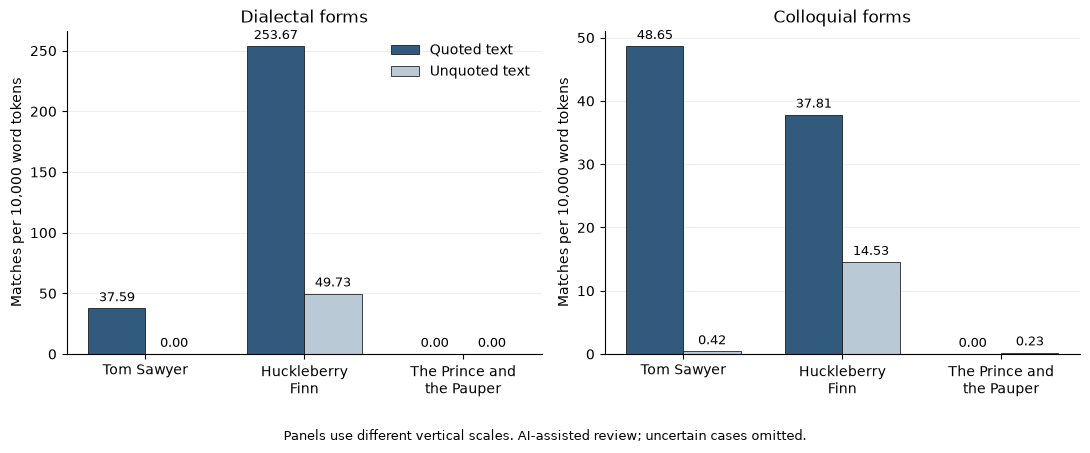

PNG: /Users/manalaltammami/Desktop/twain_child_corpus/figures/Figure_2_vernacular_context_review_20261104_225439_400313.png
PDF: /Users/manalaltammami/Desktop/twain_child_corpus/figures/Figure_2_vernacular_context_review_20261104_225439_400313.pdf


In [35]:
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime

novels = [
    "Tom Sawyer",
    "Huckleberry Finn",
    "The Prince and the Pauper",
]

sections = ["Quoted", "Unquoted"]
categories = ["dialect", "colloquial"]

fig, axes = plt.subplots(
    1, 2, figsize=(11, 4.5), sharey=False
)

x = np.arange(len(novels))
width = 0.36

colors = {
    "Quoted": "#315A7D",
    "Unquoted": "#B9C9D6",
}

for ax, category in zip(axes, categories):
    for section, offset in [
        ("Quoted", -width / 2),
        ("Unquoted", width / 2),
    ]:
        values = []

        for novel in novels:
            selected = quotation_results.loc[
                quotation_results["Novel"].eq(novel)
                & quotation_results["Section"].eq(section)
                & quotation_results["Category"].eq(category),
                "Per 10,000",
            ]

            if len(selected) != 1:
                raise ValueError(
                    f"Expected one result for "
                    f"{novel}, {section}, {category}."
                )

            values.append(float(selected.iloc[0]))

        bars = ax.bar(
            x + offset,
            values,
            width,
            label=f"{section} text",
            color=colors[section],
            edgecolor="black",
            linewidth=0.5,
        )

        ax.bar_label(
            bars,
            labels=[f"{value:.2f}" for value in values],
            padding=3,
            fontsize=9,
        )

    ax.set_title(
        "Dialectal forms"
        if category == "dialect"
        else "Colloquial forms"
    )
    ax.set_xticks(x)
    ax.set_xticklabels([
        "Tom Sawyer",
        "Huckleberry\nFinn",
        "The Prince and\nthe Pauper",
    ])
    ax.set_ylabel("Matches per 10,000 word tokens")
    ax.set_ylim(bottom=0)
    ax.margins(y=0.18)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, alpha=0.2)

axes[0].legend(frameon=False)

fig.text(
    0.5, 0.01,
    "Panels use different vertical scales. "
    "AI-assisted review; uncertain cases omitted.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.07, 1, 1])

figure_folder = BASE_PATH / "figures"
figure_folder.mkdir(exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
figure_base = figure_folder / f"Figure_2_vernacular_context_review_{timestamp}"

fig.savefig(
    figure_base.with_suffix(".png"),
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    figure_base.with_suffix(".pdf"),
    bbox_inches="tight",
)

plt.show()

print("PNG:", figure_base.with_suffix(".png"))
print("PDF:", figure_base.with_suffix(".pdf"))

## 8. Save reviewed result tables (optional)


In [38]:
from datetime import datetime
output_folder = BASE_PATH / ("vernacular_218_reviewed_results_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
output_folder.mkdir()
for name, table in {"per_book": book_results, "pooled": pooled_results,
                    "g2": g2_results, "quoted_unquoted": quotation_results}.items():
    table.to_csv(output_folder / f"{name}.csv", index=False, encoding="utf-8-sig")
print("Saved:", output_folder)


Saved: /Users/manalaltammami/Desktop/twain_child_corpus/vernacular_218_reviewed_results_20261104_225444_047057


In [40]:
# Updated counts and rates for three individual forms.
terms = ["warn't", "knowed", "hain't"]

checked = review.loc[
    review["Decision"].str.strip().eq("Include")
].copy()

checked["Normalized term"] = (
    checked["Term"].str.lower().str.replace("’", "'", regex=False)
)

totals = {
    "Twain": 248254,
    "Child": 561064,
    "Adult": 2636433,
}

rows = []

for term in terms:
    for corpus, tokens in totals.items():
        count = int(
            (
                checked["Normalized term"].eq(term)
                & checked["Corpus"].eq(corpus)
            ).sum()
        )

        rows.append({
            "Form": term,
            "Corpus": corpus,
            "Count": count,
            "Per 10,000": round(count / tokens * 10000, 2),
        })

form_results = pd.DataFrame(rows)
print(form_results.to_string(index=False))

  Form Corpus  Count  Per 10,000
warn't  Twain    309       12.45
warn't  Child     11        0.20
warn't  Adult      1        0.00
knowed  Twain    101        4.07
knowed  Child     20        0.36
knowed  Adult     55        0.21
hain't  Twain     80        3.22
hain't  Child     33        0.59
hain't  Adult    112        0.42


In [43]:
# Buxbaum's variant pairs in the current cleaned texts.
from bisect import bisect_right
import pandas as pd

PAIRS = {
    "crick / creek": ("crick", "creek"),
    "yaller / yellow": ("yaller", "yellow"),
    "gethered / gathered": ("gethered", "gathered"),
    "ben / been": ("ben", "been"),
}

BOOKS = {
    "Huckleberry Finn": "Huckleberry_Finn_narrative.txt",
    "Tom Sawyer": "Tom_Sawyer_narrative.txt",
}

# Use contextual decisions to exclude names and other false matches.
accepted_positions = {
    (row["File"], int(row["Start"]), int(row["End"]))
    for row in review.loc[
        review["Decision"].str.strip().eq("Include")
    ].to_dict("records")
}

pair_rows = []

for title, filename in BOOKS.items():
    text = source_texts[filename]
    normalized = text.lower().replace("’", "'")

    spans = quoted_spans[title]
    starts = [start for start, end in spans]

    def quotation_status(start, end):
        index = bisect_right(starts, start) - 1

        if index >= 0 and start < spans[index][1]:
            if end > spans[index][1]:
                raise ValueError("Token crosses a quotation boundary.")
            return "Quoted"

        return "Unquoted"

    # Same token rule as the other analyses.
    tokens = list(TOKEN_PATTERN.finditer(normalized))

    for label, (variant, standard) in PAIRS.items():
        counts = {
            "Variant quoted": 0,
            "Variant unquoted": 0,
            "Standard quoted": 0,
            "Standard unquoted": 0,
        }

        excluded_variants = 0

        for token in tokens:
            word = token.group()

            if word not in {variant, standard}:
                continue

            start, end = token.span()

            if word == variant:
                if (filename, start, end) not in accepted_positions:
                    excluded_variants += 1
                    continue
                form = "Variant"
            else:
                form = "Standard"

            section = quotation_status(start, end).lower()
            counts[f"{form} {section}"] += 1

        variant_total = (
            counts["Variant quoted"]
            + counts["Variant unquoted"]
        )

        standard_total = (
            counts["Standard quoted"]
            + counts["Standard unquoted"]
        )

        combined = variant_total + standard_total

        pair_rows.append({
            "Novel": title,
            "Pair": label,
            "Variant total": variant_total,
            "Standard total": standard_total,
            "Variant proportion": round(
                variant_total / combined, 3
            ) if combined else None,
            **counts,
            "Excluded variant candidates": excluded_variants,
        })

buxbaum_results = pd.DataFrame(pair_rows)

for title in BOOKS:
    print(f"\n{title}")
    print(
        buxbaum_results.loc[
            buxbaum_results["Novel"].eq(title)
        ].drop(columns="Novel").to_string(index=False)
    )

print(
    "\nVariant counts use the contextual review, including "
    "the exclusion of Ben as a name. Standard forms are "
    "exact word-token counts. Quotation status approximates "
    "dialogue and narration."
)


Huckleberry Finn
               Pair  Variant total  Standard total  Variant proportion  Variant quoted  Variant unquoted  Standard quoted  Standard unquoted  Excluded variant candidates
      crick / creek              8               3               0.727               3                 5                0                  3                            0
    yaller / yellow              6               1               0.857               2                 4                0                  1                            0
gethered / gathered              2               1               0.667               0                 2                0                  1                            0
         ben / been             27             135               0.167              27                 0               69                 66                           13

Tom Sawyer
               Pair  Variant total  Standard total  Variant proportion  Variant quoted  Variant unquoted  Standard quote

In [45]:
import re
import numpy as np
import pandas as pd
from scipy.stats import chi2

terms = [
    "monstrous",
    "lonesome",
    "comfortable",
    "pretty soon",
    "by and by",
]

def count_term(text, term):
    text = text.lower().replace("’", "'")

    # Exact words; whitespace may include line breaks.
    wording = r"\s+".join(
        re.escape(word) for word in term.split()
    )

    pattern = (
        r"(?<![a-z'’-])"
        + wording
        + r"(?![a-z'’-])"
    )

    return len(re.findall(pattern, text))

def compare_counts(k1, n1, k2, n2):
    observed = np.array([
        [k1, n1 - k1],
        [k2, n2 - k2],
    ], dtype=float)

    expected = (
        np.outer(
            observed.sum(axis=1),
            observed.sum(axis=0)
        ) / observed.sum()
    )

    mask = observed > 0

    g2 = float(
        2 * np.sum(
            observed[mask]
            * np.log(observed[mask] / expected[mask])
        )
    )

    p = chi2.sf(g2, 1)
    return round(g2, 2), f"{p:.3e}" if p else "< numerical precision"

# Calculate denominators from the loaded cleaned texts.
totals = {
    corpus: sum(
        len(tokenize(source_texts[filename]))
        for filename in files
    )
    for corpus, files in corpora.items()
}

rows = []

for term in terms:
    counts = {
        corpus: sum(
            count_term(source_texts[filename], term)
            for filename in files
        )
        for corpus, files in corpora.items()
    }

    rates = {
        corpus: counts[corpus] / totals[corpus] * 10000
        for corpus in corpora
    }

    row = {"Term": term}

    for corpus in ["Twain", "Child", "Adult"]:
        row[f"{corpus} count"] = counts[corpus]
        row[f"{corpus} per 10k"] = round(rates[corpus], 2)

    for other in ["Child", "Adult"]:
        g2, p = compare_counts(
            counts["Twain"], totals["Twain"],
            counts[other], totals[other]
        )

        row[f"G² vs {other}"] = g2
        row[f"p vs {other}"] = p
        row[f"Twain rate vs {other}"] = (
            "Higher" if rates["Twain"] > rates[other]
            else "Lower" if rates["Twain"] < rates[other]
            else "Equal"
        )

    rows.append(row)

repetition_results = pd.DataFrame(rows)
print(repetition_results.to_string(index=False))

       Term  Twain count  Twain per 10k  Child count  Child per 10k  Adult count  Adult per 10k  G² vs Child p vs Child Twain rate vs Child  G² vs Adult p vs Adult Twain rate vs Adult
  monstrous           11           0.44            1           0.02           52           0.20        19.85  8.388e-06              Higher         4.97  2.584e-02              Higher
   lonesome           19           0.77            9           0.16           37           0.14        16.34  5.303e-05              Higher        28.12  1.140e-07              Higher
comfortable           44           1.77           91           1.62          182           0.69         0.23  6.308e-01              Higher        25.78  3.820e-07              Higher
pretty soon           59           2.38            6           0.11           35           0.13       103.83  2.204e-24              Higher       171.62  3.283e-39              Higher
  by and by           20           0.81           13           0.23           80